In [1]:
print("In the name of Allah")

In the name of Allah


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans


In [9]:
df = load_iris(as_frame = True).frame

df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB


In [11]:
X = df[['sepal length (cm)', 'sepal width (cm)']]

X.head()

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6


In [12]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(X)

In [15]:
kmeans = KMeans( n_clusters = 3,
                 init = 'k-means++',
                 max_iter = 400,
                 random_state = 42 )



In [16]:
kmeans.fit(x_scaled)

KMeans(max_iter=400, n_clusters=3, random_state=42)

In [19]:
print(kmeans.labels_[:80])

[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 1 2 2 2 2 2 2 2 2 0 0 0 1 0 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1
 0 0 0 0 1 1]


In [20]:
df['clusters'] = kmeans.labels_

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,clusters
0,5.1,3.5,1.4,0.2,0,2
1,4.9,3.0,1.4,0.2,0,2
2,4.7,3.2,1.3,0.2,0,2
3,4.6,3.1,1.5,0.2,0,2
4,5.0,3.6,1.4,0.2,0,2


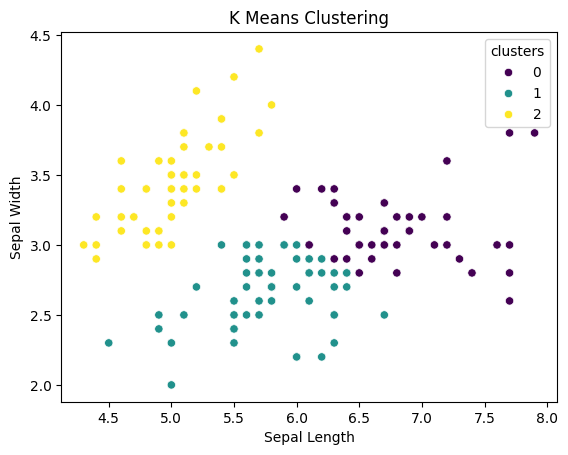

In [27]:
sns.scatterplot(
    x = df['sepal length (cm)'],
    y = df['sepal width (cm)'],
    hue = df['clusters'],
    palette = 'viridis'
)

plt.title("K Means Clustering")
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.show()

In [28]:
print(f"Inertia: {kmeans.inertia_}")

Inertia: 102.62862638978044
